## DiffGSP tutorial 3: mouse brain Slide-seqV2 dataset

In this tutorial, we demonstrate DiffGSP on the mouse brain Slide-seqV2 platform.

Unlike standard Visium data, this dataset does not contain out-of-tissue spots for parameter estimation. In addition, because the number of spots is large, we adopt a subgraph acceleration strategy to speed up computation and reduce resource usage.

The dataset used in this tutorial can be downloaded in [original study](https://singlecell.broadinstitute.org/single_cell/study/SCP815/highly-sensitive-spatial-transcriptomics-at-near-cellular-resolution-with-slide-seqv2#study-download).
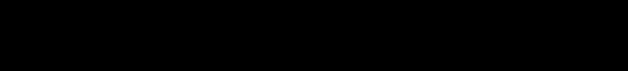
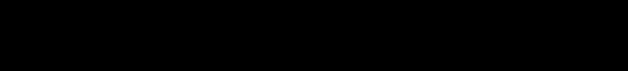

In [1]:
import DiffGSP as dg
import torch
import os
import numpy as np
import pandas as pd
import scanpy as sc
from pathlib import Path
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:0


### 1. Define input and output paths

In [2]:
data_dir = Path("/home/liujixin/datasets/SlideseqV2")
res_dir = Path("/home/liujixin/project/DiffGSP/results/SlideseqV2")

data_name = "Puck_200127_15"

data_dir = data_dir / data_name
res_dir = res_dir / data_name
res_dir.mkdir(parents=True, exist_ok=True)

### 2. Load and preprocess the data

Genes detected in fewer than 10 spots are removed. The top 2,000 spatially variable genes are then selected using the SpaGFT-based SVG selection implemented in DiffGSP.

In [3]:
dg.seed_all(42)
# load data
adata = sc.read_h5ad(data_dir / f'{data_name}.h5ad')
adata.var_names_make_unique()

# prefilter
adata = adata[:, dg.prefilter_genes(adata, min_cells=10)]
svgs = dg.select_svgs(adata, svg_method='gft_top', n_top=2000)
adata = adata[:, svgs]

Number of down-sampled spots: 2160


### 3. Save the preprocessed original data

In [4]:
# save original gene expression profiles
adata_orig = adata.copy()
adata_orig.write_h5ad(res_dir / f"{data_name}_Original.h5ad")

### 4. Run DiffGSP

Here, we run DiffGSP on the mouse brain Slide-seqV2 data. Since this dataset does not contain out-of-tissue spots for parameter estimation and has a large number of spots, we use the subgraph-accelerated version, `run_diffgsp_subgraph`, to improve speed and reduce computational resource usage.

- `partition`: partition size for the subgraph acceleration strategy. For example, `[2, 2]` divides the whole spatial tissue into 2 × 2 subgraphs.
- `variable`: parameters for inverse diffusion and smoothing. In this example, `variable=[0.1, 0.05]` means the inverse diffusion parameter is `0.1` and the smoothing parameter is `0.05`.

In [5]:
adata = sc.read_h5ad(res_dir / f"{data_name}_Original.h5ad")
# run diffgsp
k = 5
adata, paras = dg.run_diffgsp_subgraph(adata,
                                        k=k,
                                        device=device,
                                        partition=[2, 2],
                                        variable=[0.1, 0.05],
                                        data_type='Slideseq',
                                        array_key=['x', 'y'],
                                        inv_cutoff='auto')
adata.write_h5ad(res_dir / f'{data_name}_DiffGSP.h5ad')

(6831, 2000)
Found knee 0.13314246 1.3006274850581099
New para 0.1291993948276727


Test: 100%|███████████████████████████████████████████████| 4/4 [02:24<00:00, 36.13s/it, Finish=4/4]


### 5. Visualize the spatial pattern of gene Ptgds

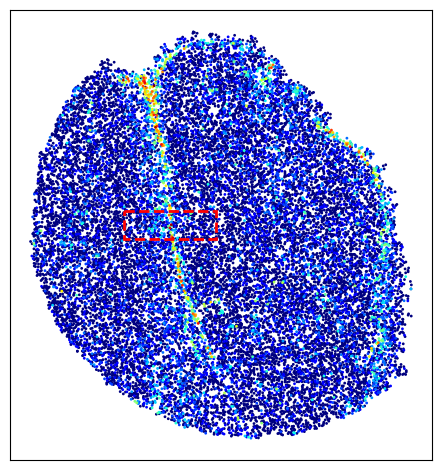

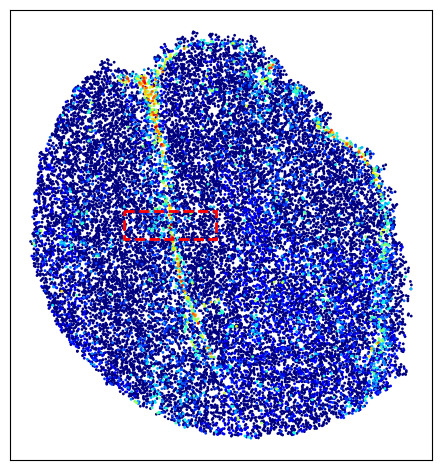

In [6]:
adata_orig = sc.read_h5ad(res_dir / f'{data_name}_Original.h5ad')
adata_diff = sc.read_h5ad(res_dir / f'{data_name}_DiffGSP.h5ad')
sc.pp.log1p(adata_orig)
sc.pp.log1p(adata_diff)

x_min, x_max, y_min, y_max = 1800, 2800, 3000, 3300
adata_orig.obs['mask'] = ((adata_orig.obsm['spatial'][:, 0] >= x_min) &
                         (adata_orig.obsm['spatial'][:, 0] <= x_max) &
                         (adata_orig.obsm['spatial'][:, 1] >= y_min) &
                         (adata_orig.obsm['spatial'][:, 1] <= y_max)).astype(str)
adata1 = adata_orig[adata_orig.obs['mask'] == 'True', :].copy()
adata_diff= adata_diff[adata_orig.obs_names]

adata_diff.obs['mask'] = ((adata_diff.obsm['spatial'][:, 0] >= x_min) &
                     (adata_diff.obsm['spatial'][:, 0] <= x_max) &
                     (adata_diff.obsm['spatial'][:, 1] >= y_min) &
                     (adata_diff.obsm['spatial'][:, 1] <= y_max)).astype(str)
adata2 = adata_diff[adata_diff.obs['mask'] == 'True', :].copy()

fig, ax = plt.subplots()
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
ax.add_patch(plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                           fill=False, color='red', linewidth=2, zorder=2, linestyle='--'))
ax = sc.pl.spatial(adata_orig, color='Ptgds', spot_size=30, ax=ax, colorbar_loc=None, title='',
               cmap='jet', show=False)[0]
ax.figure.tight_layout()
ax.figure.show()

fig, ax = plt.subplots()
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
ax.add_patch(plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                           fill=False, color='red', linewidth=2, zorder=2, linestyle='--'))
ax = sc.pl.spatial(adata_diff, color='Ptgds', spot_size=30, ax=ax, colorbar_loc=None, title='',
               cmap='jet', show=False)[0]
ax.figure.tight_layout()
ax.figure.show()

16
16


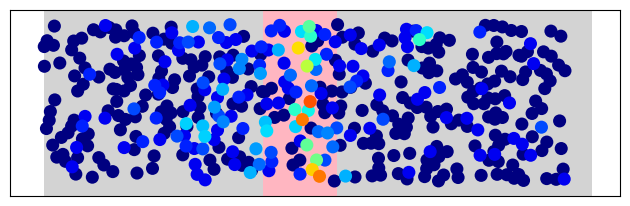

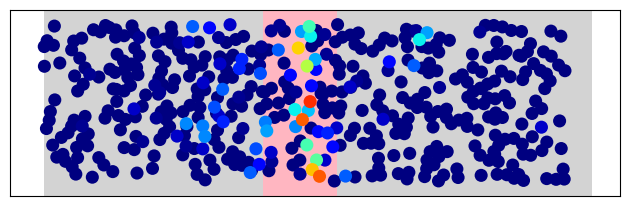

In [7]:
def x_expression(adata, gene, dx=100):
    x_min = np.min(adata.obsm['spatial'][:, 0])
    x_max = np.max(adata.obsm['spatial'][:, 0])
    x_coords = np.arange(x_min, x_max + dx, dx)
    print(len(x_coords))
    y_coords = []
    for x in x_coords:
        mask = (adata.obsm['spatial'][:, 0] >= x) & (adata.obsm['spatial'][:, 0] < x + dx)
        y_coords.append(np.array(adata[mask, [gene]].X.sum()))
    y_coords = y_coords / np.sum(y_coords)
    return x_coords, y_coords

dx = 70
left = 6
x_coords1, y_coords1 = x_expression(adata1, gene='Ptgds', dx=dx)
x_coords2, y_coords2 = x_expression(adata2, gene='Ptgds', dx=dx)

fig, ax1 = plt.subplots()
ax1.xaxis.set_visible(False)
ax1.yaxis.set_visible(False)
x_ranges = [(x_coords1.min(), x_coords1[left], 'lightgray'), (x_coords1[left], x_coords1[left+2], 'lightpink'),
            (x_coords1[left+2], x_coords1.max(), 'lightgray')]
for x_start, x_end, color in x_ranges:
    ax1.axvspan(x_start, x_end, facecolor=color, alpha=1, zorder=0)
ax1 = sc.pl.spatial(adata1, color='Ptgds', spot_size=25, colorbar_loc=None, title='', ax=ax1, cmap='jet',
             vmin=0, vmax=7, show=False)[0]
ax1.figure.tight_layout()
ax1.figure.show()

fig, ax2 = plt.subplots()
ax2.xaxis.set_visible(False)
ax2.yaxis.set_visible(False)
x_ranges = [(x_coords1.min(), x_coords1[left], 'lightgray'), (x_coords1[left], x_coords1[left+2], 'lightpink'),
            (x_coords1[left+2], x_coords1.max(), 'lightgray')]
for x_start, x_end, color in x_ranges:
    ax2.axvspan(x_start, x_end, facecolor=color, alpha=1, zorder=0)
ax2 = sc.pl.spatial(adata2, color='Ptgds', spot_size=25, colorbar_loc=None, title='', ax=ax2, cmap='jet',
              vmin=1, vmax=7, show=False)[0]
ax2.figure.tight_layout()
ax2.figure.show()